# PRACTICUM DE ÎNVĂȚARE AUTOMATĂ: CODUL ȘI ALGORITMUL KNN
**Teme:** Preprocesarea datelor, Codificare categorială, Normalizare, Algoritmul K cei mai apropiați vecini (KNN), Ajustarea hiperparametrilor, Valori metrice ale distanței, Intel® Extension for Scikit-learn și Combaterea supraantrenării (Overfitting).

### Pregătire (Google Colab)
Încărcarea datelor și a bibliotecilor. Dacă fișierul `Orange_Telecom_Churn_Data.csv` lipsește, se deschide fereastra de încărcare.

In [1]:
!pip install -q scikit-learn-intelex

import os
FILE = 'Orange_Telecom_Churn_Data.csv'
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()          # alegeți Orange_Telecom_Churn_Data.csv
    except ImportError:
        pass

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
%matplotlib inline

RANDOM_STATE = 42

### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante
În setul de date Orange Telecom Churn, coloanele `state`, `area_code` și `phone_number` au fost eliminate în notebook. Scrieți un bloc de cod în Pandas care analizează cardinalitatea unică a fiecărei coloane categoriale rămase și eliminate. Explicați din punct de vedere matematic de ce aplicarea `OneHotEncoder` sau `LabelBinarizer` pe o coloană cu sute de valori unice (de exemplu, `phone_number`) va distruge eficiența spațială și va genera un risc ridicat de supraantrenare (overfitting) pentru algoritmul KNN.

In [2]:
import pandas as pd

df_raw = pd.read_csv(FILE)
print('Dimensiune:', df_raw.shape)

# Cardinalitatea fiecărei coloane categoriale (non-numerice) + area_code
cat_cols = df_raw.select_dtypes(exclude='number').columns.tolist() + ['area_code']
card = df_raw[cat_cols].nunique().sort_values(ascending=False)
print('\nCardinalitatea coloanelor categoriale:')
print(card)

dropped = ['state', 'area_code', 'phone_number']
print('\nColoane eliminate:', {c: df_raw[c].nunique() for c in dropped})

# Preprocesarea standard din notebook
df = df_raw.drop(columns=dropped).copy()
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    df[col] = lb.fit_transform(df[col].astype(str)).ravel()

print('\nColoane categoriale rămase:', {c: df[c].nunique() for c in ['intl_plan', 'voice_mail_plan', 'churned']})
print('Dimensiunea după One-Hot pe phone_number ar fi:',
      df_raw.shape[0], 'x', df_raw.shape[1] - 1 + df_raw['phone_number'].nunique() - 1, 'coloane')
df.head()

Dimensiune: (5000, 21)

Cardinalitatea coloanelor categoriale:
phone_number       5000
state                51
area_code             3
intl_plan             2
voice_mail_plan       2
churned               2
dtype: int64

Coloane eliminate: {'state': 51, 'area_code': 3, 'phone_number': 5000}

Coloane categoriale rămase: {'intl_plan': 2, 'voice_mail_plan': 2, 'churned': 2}
Dimensiunea după One-Hot pe phone_number ar fi: 5000 x 5019 coloane


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,107,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,137,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,84,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,75,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


**Explicație matematică.**

- `phone_number` are **5000 de valori unice la 5000 de rânduri** – este practic un identificator. `OneHotEncoder` creează câte o coloană pentru fiecare valoare ⇒ +5000 de dimensiuni, matrice 5000×5000 aproape complet nulă (memorie O(n²) în format dens, fiecare rând conține un singur 1). `state` ar adăuga încă 51 de coloane.
- **Distanța devine lipsită de informație.** Pentru doi clienți diferiți *i ≠ j*, vectorii one-hot diferă în exact două poziții, deci contribuția acestor coloane la distanța euclidiană este mereu $\sqrt{(1-0)^2+(0-1)^2}=\sqrt{2}$, *pentru orice pereche*. Se adaugă o constantă identică tuturor perechilor, care nu ajută la diferențiere, dar „îneacă” relativ caracteristicile utile (după scalare în [0,1] ele contribuie cu valori < 1), iar distanțele devin aproape egale (vezi blestemul dimensionalității, Ex. 10).
- **Supraantrenare.** O coloană unică pe client poate identifica precis un singur exemplu: modelul „memorează” clienții în loc să învețe tipare; pe date noi (numere de telefon necunoscute) coloanele sunt toate 0 ⇒ nicio generalizare. Numărul de dimensiuni (5000+) ≥ numărul de exemple ⇒ spațiu extrem de rar, vecinii „cei mai apropiați” nu mai sunt semnificativ apropiați.
- `area_code` are doar 3 valori, dar nu are sens ordinal/numeric și nu poartă informație despre churn, iar `state` are cardinalitate mare relativ la date (≈100 clienți/stat) – de aceea au fost eliminate.

### Exercițiul 2: Impactul scalării datelor asupra distanței euclidiene
Folosind `MinMaxScaler`, toate caracteristicile numerice sunt aduse în intervalul [0, 1]. Să presupunem că avem două caracteristici: `account_length` (valori de la 1 la 250) și `total_day_charge` (valori de la 0 la 100). Calculați manual sau scrieți cod care arată cum distanța euclidiană între doi clienți este distorsionată dacă nu se aplică scalarea. Ce se întâmplă dacă se folosește `StandardScaler` în loc de `MinMaxScaler` atunci când în distribuția datelor există valori anormale (outliers)?

In [3]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np

# Doi clienți: diferă cu 50 de zile la account_length și cu 40 $ la total_day_charge
A = np.array([100, 20.0])
B = np.array([150, 60.0])
print('Distanța fără scalare:', np.linalg.norm(A - B).round(3))
print('  contribuția account_length   :', (A[0]-B[0])**2, ' -> ', round((A[0]-B[0])**2 / np.sum((A-B)**2) * 100, 1), '%')
print('  contribuția total_day_charge :', (A[1]-B[1])**2, ' -> ', round((A[1]-B[1])**2 / np.sum((A-B)**2) * 100, 1), '%')

# Aceeași comparație manuală cu min/max dați în enunț: account_length 1..250, charge 0..100
mins, maxs = np.array([1, 0]), np.array([250, 100])
As, Bs = (A - mins) / (maxs - mins), (B - mins) / (maxs - mins)
print('\nDupă MinMax:', np.linalg.norm(As - Bs).round(3),
      '| diferențe pe axe:', np.abs(As - Bs).round(3))

# Pe datele reale: care vecin e „cel mai apropiat” se schimbă după scalare
X2 = df_raw[['account_length', 'total_day_charge']].values
q = 0
d_raw = np.linalg.norm(X2 - X2[q], axis=1)
Xs = MinMaxScaler().fit_transform(X2)
d_mm = np.linalg.norm(Xs - Xs[q], axis=1)
print('\nCei mai apropiați 5 vecini ai clientului 0 fără scalare :', np.argsort(d_raw)[1:6])
print('Cei mai apropiați 5 vecini ai clientului 0 cu MinMax    :', np.argsort(d_mm)[1:6])

Distanța fără scalare: 64.031
  contribuția account_length   : 2500.0  ->  61.0 %
  contribuția total_day_charge : 1600.0  ->  39.0 %

După MinMax: 0.448 | diferențe pe axe: [0.201 0.4  ]

Cei mai apropiați 5 vecini ai clientului 0 fără scalare : [2236 4181  301 3458  877]
Cei mai apropiați 5 vecini ai clientului 0 cu MinMax    : [4181  301 3458  877 2236]


MinMax   : valori normale în [ 0.000,  0.051] (lățime 0.051), outlier = 1.00
Standard : valori normale în [-0.458,  0.272] (lățime 0.731), outlier = 13.98
Robust   : valori normale în [-1.719,  1.533] (lățime 3.252), outlier = 62.54


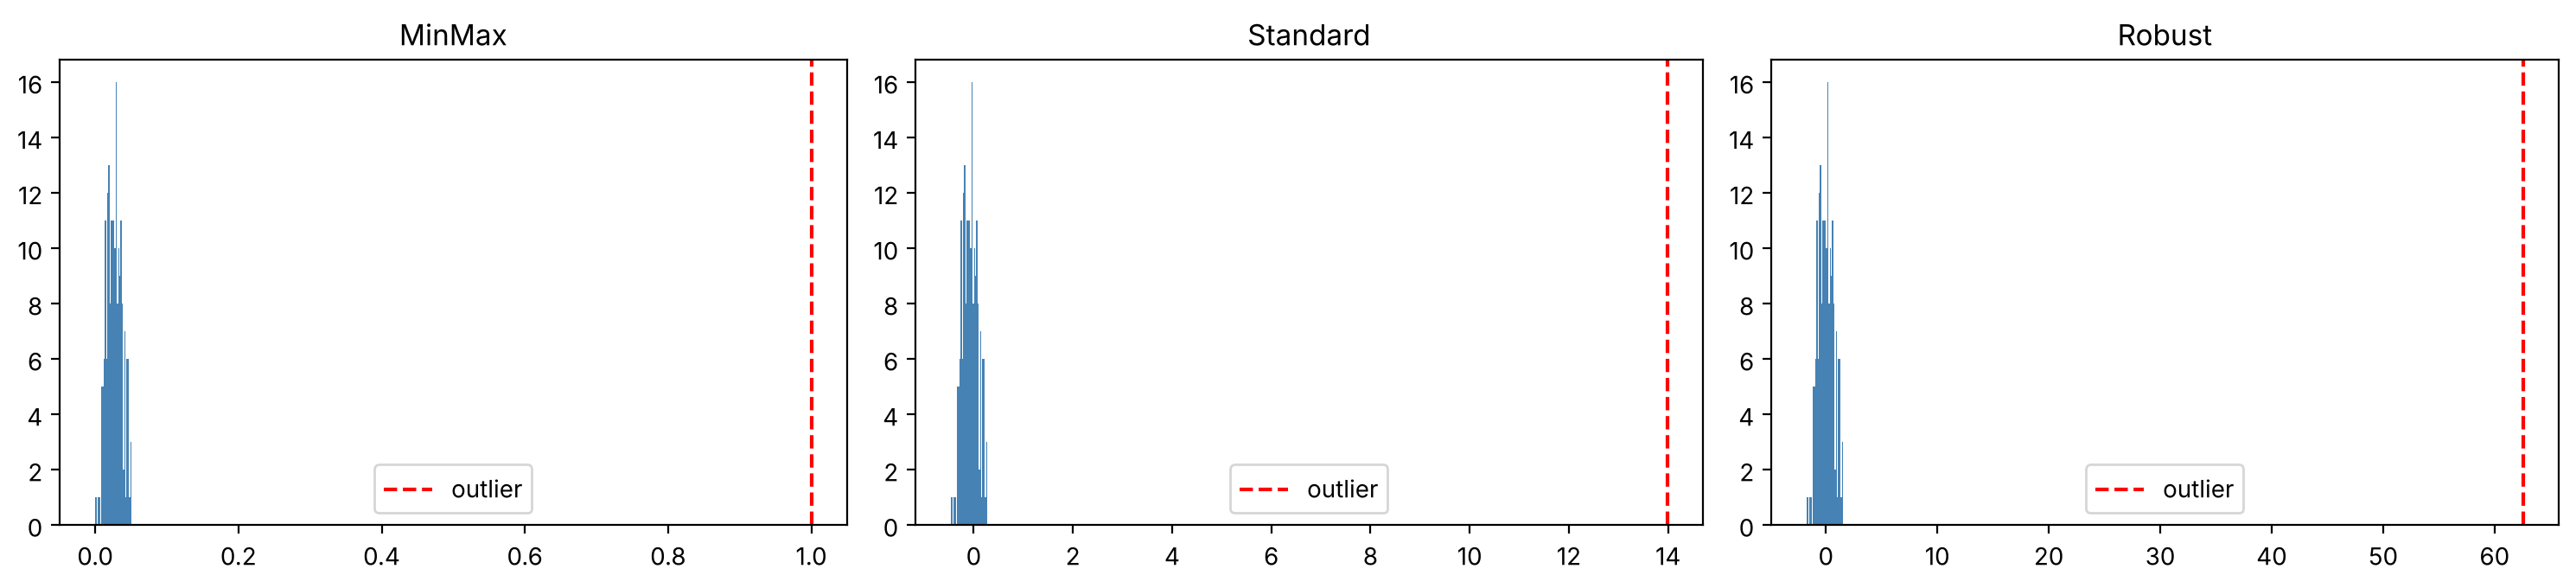

In [4]:
# Impactul outlier-ilor: MinMaxScaler vs StandardScaler (vs RobustScaler)
from sklearn.preprocessing import RobustScaler

rng = np.random.RandomState(0)
x = np.r_[rng.normal(50, 10, 200), [1000]]          # 200 valori normale + 1 outlier extrem
x = x.reshape(-1, 1)

res = {}
for name, sc in [('MinMax', MinMaxScaler()), ('Standard', StandardScaler()), ('Robust', RobustScaler())]:
    z = sc.fit_transform(x).ravel()
    res[name] = z
    print(f'{name:9s}: valori normale în [{z[:-1].min():6.3f}, {z[:-1].max():6.3f}] '
          f'(lățime {z[:-1].max()-z[:-1].min():.3f}), outlier = {z[-1]:.2f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (name, z) in zip(ax, res.items()):
    a.hist(z[:-1], bins=30, color='steelblue'); a.axvline(z[-1], color='r', ls='--', label='outlier')
    a.set_title(name); a.legend()
plt.tight_layout(); plt.show()

**Concluzii.**

- Fără scalare, distanța euclidiană este dominată de caracteristica cu domeniul mai mare: aici `account_length` (1–250) dă ~61% din pătratul distanței, deși o diferență de 40 $ la `total_day_charge` este relativ mult mai importantă (40% din domeniu față de 20%). După `MinMaxScaler` ambele variabile au aceeași „greutate” (domeniu [0,1]), iar ordinea celor mai apropiați vecini se schimbă – deci se pot schimba și predicțiile KNN.
- **Cu outlier-i:** `MinMaxScaler` folosește min și max ⇒ un singur outlier „comprimă” toate valorile normale într-un interval foarte îngust (aici doar ~0.05 din [0,1]), caracteristica devine aproape inutilă pentru distanță. `StandardScaler` folosește media și abaterea standard, care sunt și ele influențate de outlier (σ crește), dar mai puțin: valorile normale rămân pe o lățime mai mare, iar outlier-ul primește un z-score foarte mare (~14). Totuși, nici `StandardScaler` nu este robust – media și σ sunt deplasate și nu garantează un interval fix. Cea mai bună alegere în prezența outlier-ilor este `RobustScaler` (mediana și IQR) sau eliminarea/limitarea outlier-ilor înainte de scalare.

### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn
În notebook este activată extensia `from sklearnex import patch_sklearn; patch_sklearn()`. Explicați cum această bibliotecă accelerează operațiunile de căutare a celor mai apropiați vecini (de exemplu, utilizând structuri de date indexate precum KD-Tree sau Ball-Tree, optimizate cu instrucțiuni AVX-512). Scrieți un fragment de cod care măsoară timpul de execuție (`timeit`) pentru antrenarea `KNeighborsClassifier` cu și fără patch-ul Intel pe un set sintetic de 100.000 de obiecte.

**Explicație.** Intel® Extension for Scikit-learn (`sklearnex`) înlocuiește, prin `patch_sklearn()`, implementările unor estimatori sklearn (KNN, KMeans, SVC, RandomForest, PCA, LogisticRegression…) cu versiuni din biblioteca **oneDAL** (oneAPI Data Analytics Library), păstrând aceeași interfață:

- **Structuri de date indexate:** pentru dimensiuni mici oneDAL construiește un **KD-Tree** (împarte recursiv spațiul pe axe) – căutarea vecinilor coboară O(log n) în loc de O(n) pe interogare; pentru dimensiuni mari folosește **brute-force** optimizat. (Ball-Tree, utilizat în sklearn, partiționează în hipersfere și e util pentru metrici non-euclidiene.)
- **Vectorizare SIMD (AVX2/AVX-512):** calculul distanțelor ‖x−y‖² = ‖x‖² + ‖y‖² − 2xᵀy se reduce la înmulțiri de matrici (BLAS / Intel MKL) care procesează 8–16 numere float într-o singură instrucțiune.
- **Paralelism multi-thread** (Intel TBB) pe toate nucleele, blocare pe cache (cache blocking), selecție eficientă a top-K, memorie fără copii inutile.
- Pentru KNN, `fit()` doar memorează datele / construiește arborele, deci accelerarea cea mai mare se vede la `predict()`.

> Notă: accelerarea depinde de procesor. Colab rulează de obicei pe Intel Xeon, deci efectul se vede; pe AMD/ARM câștigul poate fi mai mic.

In [5]:
import time
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Crearea de date sintetice
rng = np.random.RandomState(RANDOM_STATE)
X = rng.rand(100000, 10)
y = rng.randint(0, 2, 100000)
X_query = X[:2000]          # predict pe 2000 de puncte (pe toate 100k ar dura foarte mult fără patch)

def benchmark(label):
    from sklearn.neighbors import KNeighborsClassifier   # re-import după patch/unpatch
    knn = KNeighborsClassifier(n_neighbors=5)
    t0 = time.perf_counter(); knn.fit(X, y);        t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); knn.predict(X_query); t_pred = time.perf_counter() - t0
    print(f'{label:12s} fit: {t_fit:7.3f} s | predict(2000): {t_pred:7.3f} s | clasa: {type(knn).__module__}')
    return t_fit, t_pred

from sklearnex import patch_sklearn, unpatch_sklearn

# 1) fără patch
unpatch_sklearn()
t_std = benchmark('sklearn')

# 2) cu patch Intel
patch_sklearn()
t_intel = benchmark('sklearnex')

print(f'\nAccelerare fit: x{t_std[0]/t_intel[0]:.1f}, predict: x{t_std[1]/t_intel[1]:.1f}')

sklearn      fit:   0.132 s | predict(2000):   0.499 s | clasa: sklearn.neighbors._classification
sklearnex    fit:   0.052 s | predict(2000):   0.066 s | clasa: sklearnex.neighbors.knn_classification

Accelerare fit: x2.5, predict: x7.5


Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [6]:
# Același lucru cu modulul timeit (media pe câteva repetări)
import timeit
setup = 'from sklearn.neighbors import KNeighborsClassifier; m = KNeighborsClassifier(5)'
unpatch_sklearn()
t1 = min(timeit.repeat('m.fit(X, y); m.predict(X_query)', setup=setup, globals=globals(), number=1, repeat=3))
patch_sklearn()
t2 = min(timeit.repeat('m.fit(X, y); m.predict(X_query)', setup=setup, globals=globals(), number=1, repeat=3))
print(f'timeit (fit+predict): sklearn = {t1:.3f} s, sklearnex = {t2:.3f} s, accelerare x{t1/t2:.1f}')

unpatch_sklearn()   # restul notebook-ului rulează cu sklearn standard

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


timeit (fit+predict): sklearn = 0.449 s, sklearnex = 0.087 s, accelerare x5.1


### Exercițiul 4: Analiza matematică a metricilor de distanță (Minkowski, Manhattan, Euclidiană)
Implementați de la zero o funcție Python care calculează distanța Minkowski între două puncte $x$ și $y$ pentru o putere arbitrară $p \ge 1$. Demonstrați prin cod cum modificarea parametrului `p` de la 1 (Manhattan) la 2 (Euclidiană) și la valori mari ($p \to \infty$, distanța Cebîșev) influențează granițele de decizie ale clasificatorului KNN pe un set de date binar bidimensional.

In [7]:
def minkowski_distance(x, y, p):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if p < 1:
        raise ValueError('p trebuie să fie >= 1 (altfel nu este metrică)')
    if np.isinf(p):
        return np.max(np.abs(x - y))            # limita p -> inf: distanța Cebîșev
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

# Testarea funcției
a, b = np.array([0, 0]), np.array([3, 4])
from scipy.spatial.distance import minkowski
for p in [1, 2, 3, 10, 50, np.inf]:
    ref = np.max(np.abs(a-b)) if np.isinf(p) else minkowski(a, b, p)
    print(f'p={p:>4}: distanța = {minkowski_distance(a, b, p):.4f}   (scipy: {ref:.4f})')

p=   1: distanța = 7.0000   (scipy: 7.0000)
p=   2: distanța = 5.0000   (scipy: 5.0000)
p=   3: distanța = 4.4979   (scipy: 4.4979)
p=  10: distanța = 4.0220   (scipy: 4.0220)
p=  50: distanța = 4.0000   (scipy: 4.0000)
p= inf: distanța = 4.0000   (scipy: 4.0000)


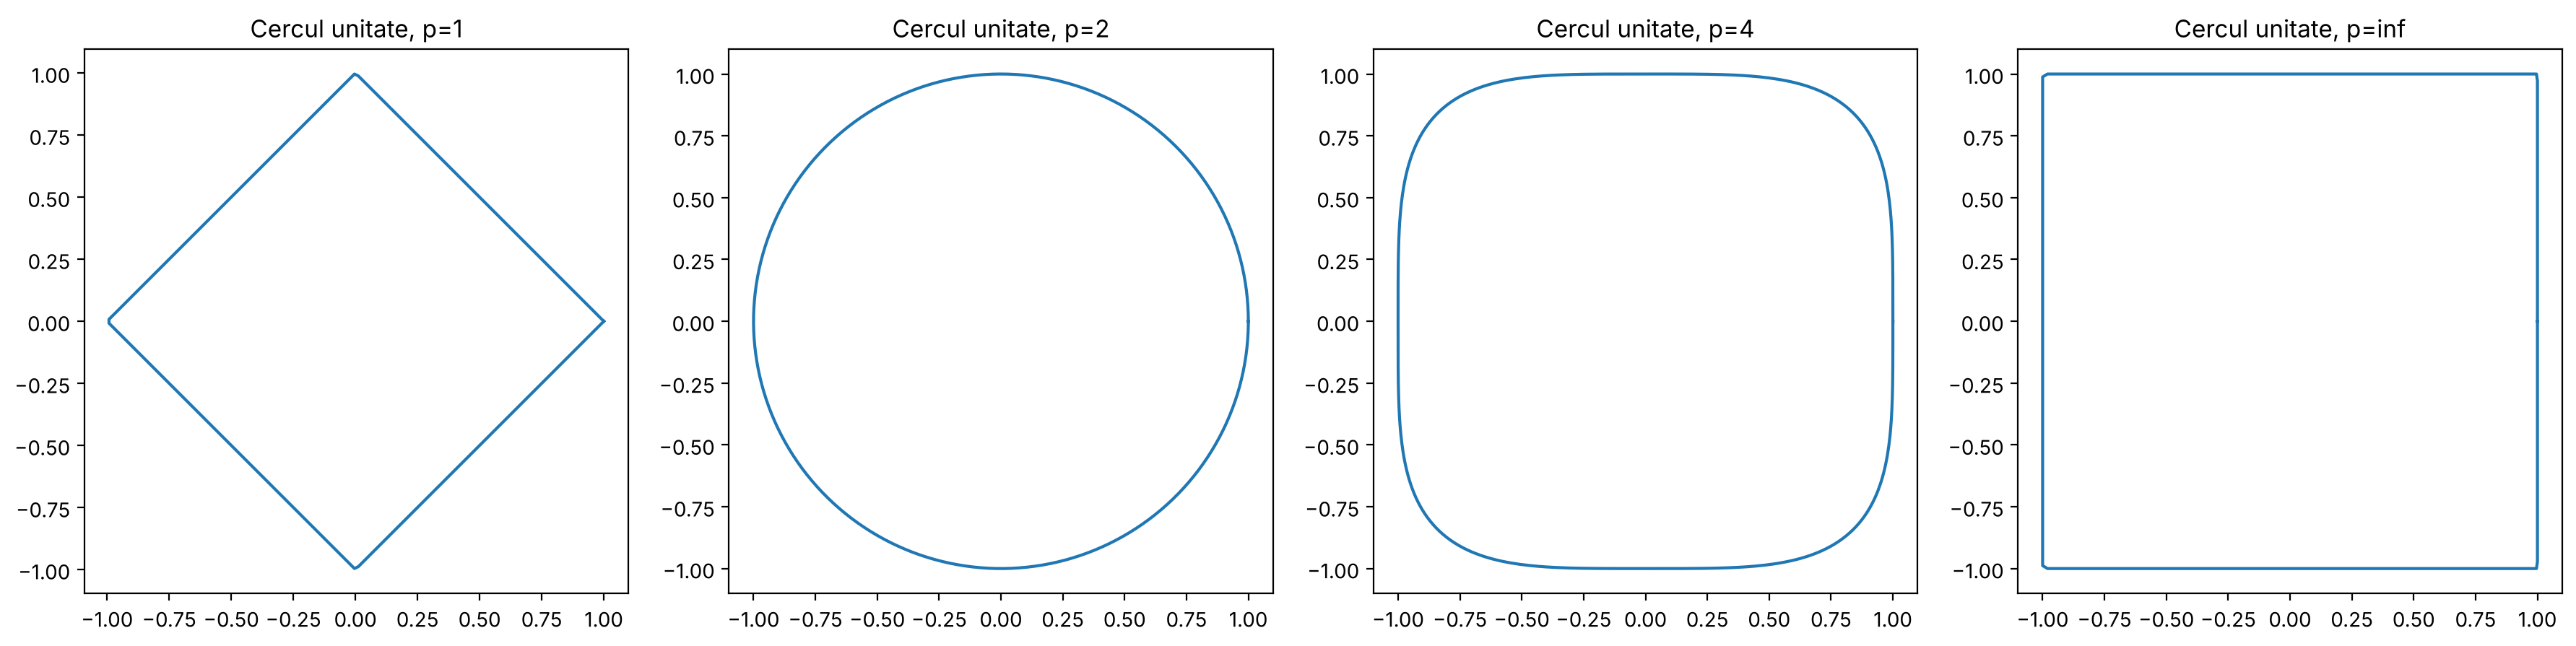

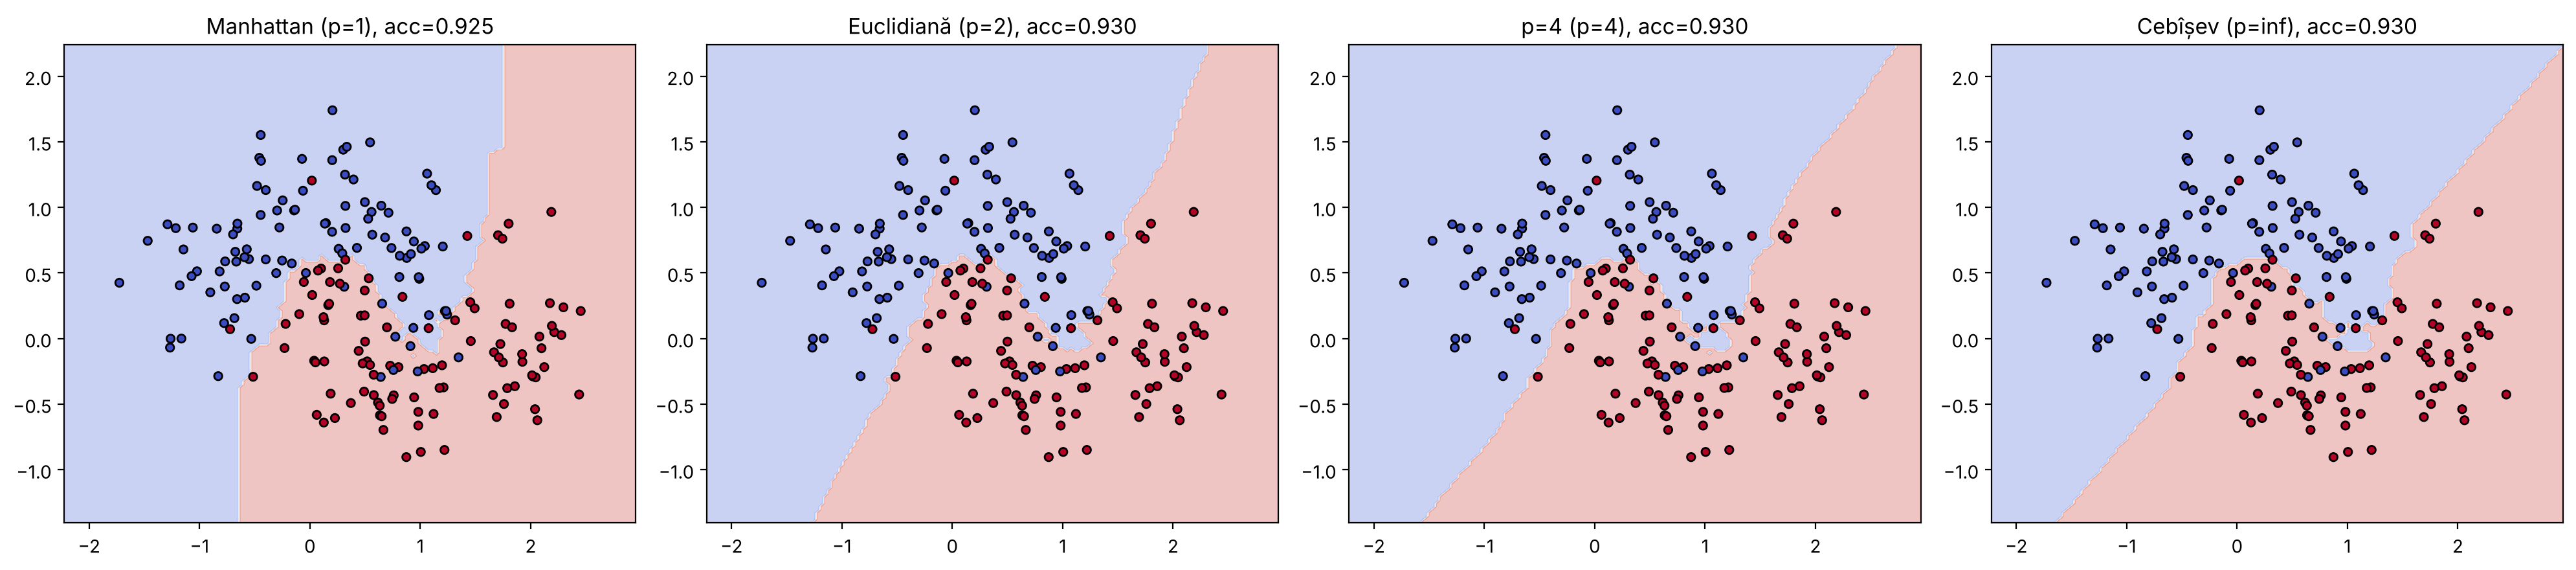

Predicții identice (funcția proprie vs sklearn, p=1): True


In [8]:
from sklearn.datasets import make_moons
from sklearn.neighbors import KNeighborsClassifier

# Set de date binar bidimensional
X2d, y2d = make_moons(n_samples=200, noise=0.3, random_state=RANDOM_STATE)

# Cercurile unitate: forma „bilei” în care se caută vecinii
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
t = np.linspace(0, 2*np.pi, 400)
for ax, p in zip(axes, [1, 2, 4, np.inf]):
    dirs = np.c_[np.cos(t), np.sin(t)]
    r = np.array([1 / minkowski_distance(d, [0, 0], p) for d in dirs])   # punctele cu distanța 1
    ax.plot(dirs[:, 0]*r, dirs[:, 1]*r); ax.set_aspect('equal'); ax.set_title(f'Cercul unitate, p={p}')
plt.tight_layout(); plt.show()

# Granițele de decizie KNN (k=15) pentru diferite p, folosind funcția noastră ca metrică
xx, yy = np.meshgrid(np.linspace(X2d[:, 0].min()-.5, X2d[:, 0].max()+.5, 150),
                     np.linspace(X2d[:, 1].min()-.5, X2d[:, 1].max()+.5, 150))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (p, name) in zip(axes, [(1, 'Manhattan'), (2, 'Euclidiană'), (4, 'p=4'), (np.inf, 'Cebîșev')]):
    if np.isinf(p):
        knn = KNeighborsClassifier(n_neighbors=15, metric='chebyshev')
    else:
        knn = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=p)
    knn.fit(X2d, y2d)
    Z = knn.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X2d[:, 0], X2d[:, 1], c=y2d, cmap='coolwarm', edgecolor='k', s=20)
    ax.set_title(f'{name} (p={p}), acc={knn.score(X2d, y2d):.3f}')
plt.tight_layout(); plt.show()

# Verificare: metrica proprie dă aceleași predicții ca sklearn
knn_custom = KNeighborsClassifier(n_neighbors=15, metric=lambda u, v: minkowski_distance(u, v, 1)).fit(X2d, y2d)
knn_sk = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=1).fit(X2d, y2d)
print('Predicții identice (funcția proprie vs sklearn, p=1):',
      np.array_equal(knn_custom.predict(X2d[:50]), knn_sk.predict(X2d[:50])))

**Concluzii.** Parametrul `p` schimbă forma „vecinătății”: la **p=1 (Manhattan)** bila este un romb, distanța însumează diferențele pe axe, iar granițele de decizie au segmente orientate pe axe/diagonale (mai „colțuroase”); la **p=2 (Euclidiană)** bila este un cerc – granițe netede, invariante la rotație; la **p→∞ (Cebîșev)** bila devine un pătrat, contează doar diferența maximă pe o axă, granițele devin în trepte, paralele cu axele. Distanța scade monoton cu p (pentru (3,4): 7 → 5 → 4). Pentru date 2D cu zgomot moderat, diferența de acuratețe e mică, dar formele granițelor diferă vizibil.

### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare
Așa cum s-a menționat în întrebarea 5 a notebook-ului, rularea KNN cu parametrul `weights='distance'` sau $K=1$ pe setul complet de date (fără împărțire train/test) oferă o precizie de 1.0 (100%). Explicați în detaliu fenomenul de memorare (supraantrenare extremă) în KNN. Ce se întâmplă cu cel mai apropiat vecin al punctului $x_i$ dacă eșantionul de antrenare include chiar punctul $x_i$?

In [9]:
# Experiment cu K=1 pe eșantionul de antrenare
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df.drop(columns='churned').values
y = df['churned'].values

X_mm = MinMaxScaler().fit_transform(X)

for params in [dict(n_neighbors=1), dict(n_neighbors=3, weights='distance'), dict(n_neighbors=3), dict(n_neighbors=5)]:
    knn = KNeighborsClassifier(**params).fit(X_mm, y)
    print(f'{str(params):40s} acuratețe pe datele de antrenare = {accuracy_score(y, knn.predict(X_mm)):.4f}')

# Cine este cel mai apropiat vecin al lui x_i?
knn1 = KNeighborsClassifier(n_neighbors=1).fit(X_mm, y)
dist, idx = knn1.kneighbors(X_mm[:5])
print('\nIndicii punctelor:', list(range(5)))
print('Cel mai apropiat vecin:', idx.ravel(), ' distanța:', dist.ravel())

# Evaluare corectă: train/test
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
sc = MinMaxScaler().fit(X_tr)
for params in [dict(n_neighbors=1), dict(n_neighbors=3, weights='distance')]:
    m = KNeighborsClassifier(**params).fit(sc.transform(X_tr), y_tr)
    print(f'{str(params):40s} train = {m.score(sc.transform(X_tr), y_tr):.4f} | test = {m.score(sc.transform(X_te), y_te):.4f}')

{'n_neighbors': 1}                       acuratețe pe datele de antrenare = 1.0000
{'n_neighbors': 3, 'weights': 'distance'} acuratețe pe datele de antrenare = 1.0000


{'n_neighbors': 3}                       acuratețe pe datele de antrenare = 0.9422
{'n_neighbors': 5}                       acuratețe pe datele de antrenare = 0.9284

Indicii punctelor: [0, 1, 2, 3, 4]
Cel mai apropiat vecin: [0 1 2 3 4]  distanța: [0.00000000e+00 4.21468485e-08 4.21468485e-08 0.00000000e+00
 0.00000000e+00]


{'n_neighbors': 1}                       train = 1.0000 | test = 0.8753
{'n_neighbors': 3, 'weights': 'distance'} train = 1.0000 | test = 0.8987


**Explicație.** KNN este un algoritm „leneș” (lazy learning): `fit()` doar **memorează** întregul set de antrenare. Dacă evaluăm pe aceleași date, pentru fiecare punct $x_i$ cel mai apropiat vecin este **chiar $x_i$**, cu distanța $d(x_i, x_i)=0$. Deci:

- la **K=1** predicția este eticheta lui $x_i$ însuși ⇒ acuratețe 100% (excepție: dubluri identice cu etichete diferite);
- la **`weights='distance'`** ponderea este $1/d$, iar pentru $d=0$ ponderea este infinită – sklearn atribuie atunci clasa punctelor cu distanța 0, deci iarăși răspunsul este eticheta lui $x_i$ ⇒ 100% pentru orice K.

Este o **supraantrenare extremă (memorare)**: modelul are varianță maximă, granița de decizie trece în jurul fiecărui punct, inclusiv al zgomotului. Acuratețea de 1.0 nu spune nimic despre generalizare – pe eșantionul de test acuratețea scade (vezi mai sus). Pentru evaluare corectă se folosește train/test split sau validarea încrucișată (Ex. 7).

### Exercițiul 6: Implementarea propriului algoritm KNN de la zero
Fără a folosi clase din `sklearn`, scrieți propria clasă Python `CustomKNN` care implementează interfețele `fit(X, y)` și `predict(X_test, k)`. Clasa trebuie să utilizeze distanța euclidiană, să suporte votul majoritar simplu și să proceseze eficient matrici NumPy. Testați clasa pe o submulțime mică de date privind abandonul (churn).

In [10]:
class CustomKNN:
    """KNN simplu: distanța euclidiană + vot majoritar, complet vectorizat în NumPy."""

    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        return self

    def _distances(self, X_test):
        # ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a·b  -> o singură înmulțire de matrici, fără bucle
        a2 = np.sum(X_test ** 2, axis=1)[:, None]
        b2 = np.sum(self.X_train ** 2, axis=1)[None, :]
        d2 = a2 + b2 - 2 * X_test @ self.X_train.T
        return np.sqrt(np.maximum(d2, 0))

    def predict(self, X_test, k=None, batch_size=1000):
        k = k or self.k
        X_test = np.asarray(X_test, dtype=float)
        preds = []
        for start in range(0, len(X_test), batch_size):          # pe loturi -> memorie limitată
            D = self._distances(X_test[start:start + batch_size])
            nn = np.argpartition(D, kth=k - 1, axis=1)[:, :k]     # indicii celor k vecini, O(n)
            labels = self.y_train[nn]
            # vot majoritar: numărăm voturile pentru fiecare clasă
            votes = np.stack([(labels == c).sum(axis=1) for c in self.classes_], axis=1)
            preds.append(self.classes_[np.argmax(votes, axis=1)])
        return np.concatenate(preds)

    def score(self, X, y, k=None):
        return np.mean(self.predict(X, k) == np.asarray(y))


# Test pe o submulțime a datelor de churn
sub = df.sample(1500, random_state=RANDOM_STATE)
Xs_, ys_ = sub.drop(columns='churned').values, sub['churned'].values
X_tr, X_te, y_tr, y_te = train_test_split(Xs_, ys_, test_size=0.3, stratify=ys_, random_state=RANDOM_STATE)
sc = MinMaxScaler().fit(X_tr)
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)

custom = CustomKNN().fit(X_tr, y_tr)
for k in [1, 3, 5, 7]:
    p_custom = custom.predict(X_te, k=k)
    p_sk = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr).predict(X_te)
    print(f'k={k}: CustomKNN acc = {np.mean(p_custom == y_te):.4f} | sklearn acc = {np.mean(p_sk == y_te):.4f} '
          f'| predicții identice: {np.mean(p_custom == p_sk)*100:.1f}%')

k=1: CustomKNN acc = 0.8911 | sklearn acc = 0.8911 | predicții identice: 100.0%
k=3: CustomKNN acc = 0.9156 | sklearn acc = 0.9156 | predicții identice: 100.0%
k=5: CustomKNN acc = 0.9289 | sklearn acc = 0.9289 | predicții identice: 100.0%
k=7: CustomKNN acc = 0.9200 | sklearn acc = 0.9200 | predicții identice: 100.0%


### Exercițiul 7: Validare încrucișată (Cross-Validation) pentru alegerea K-ului optim
Pentru a evita capcana evaluării pe eșantionul de antrenare, implementați procedura 5-Fold Cross-Validation utilizând `StratifiedKFold` din Scikit-learn. Scrieți un script care calculează precizia medie și deviația standard pentru valori K de la 1 la 30. Generați un grafic al erorilor de validare în funcție de K și determinați valoarea optimă.

  K  acc medie      std
  1     0.8732   0.0088
  2     0.8898   0.0026
  3     0.8992   0.0048
  4     0.8916   0.0060
  5     0.9016   0.0036   <-- optim
  6     0.8910   0.0040
  7     0.8978   0.0040
  8     0.8922   0.0041
  9     0.9012   0.0041
 10     0.8952   0.0039
 11     0.9012   0.0025
 12     0.8968   0.0033
 13     0.9014   0.0036
 14     0.8962   0.0031
 15     0.8998   0.0048
 16     0.8946   0.0035
 17     0.8996   0.0033
 18     0.8912   0.0028
 19     0.8954   0.0034
 20     0.8884   0.0034
 21     0.8928   0.0051
 22     0.8882   0.0039
 23     0.8920   0.0044
 24     0.8876   0.0058
 25     0.8896   0.0054
 26     0.8874   0.0042
 27     0.8896   0.0048
 28     0.8866   0.0030
 29     0.8886   0.0029
 30     0.8850   0.0038


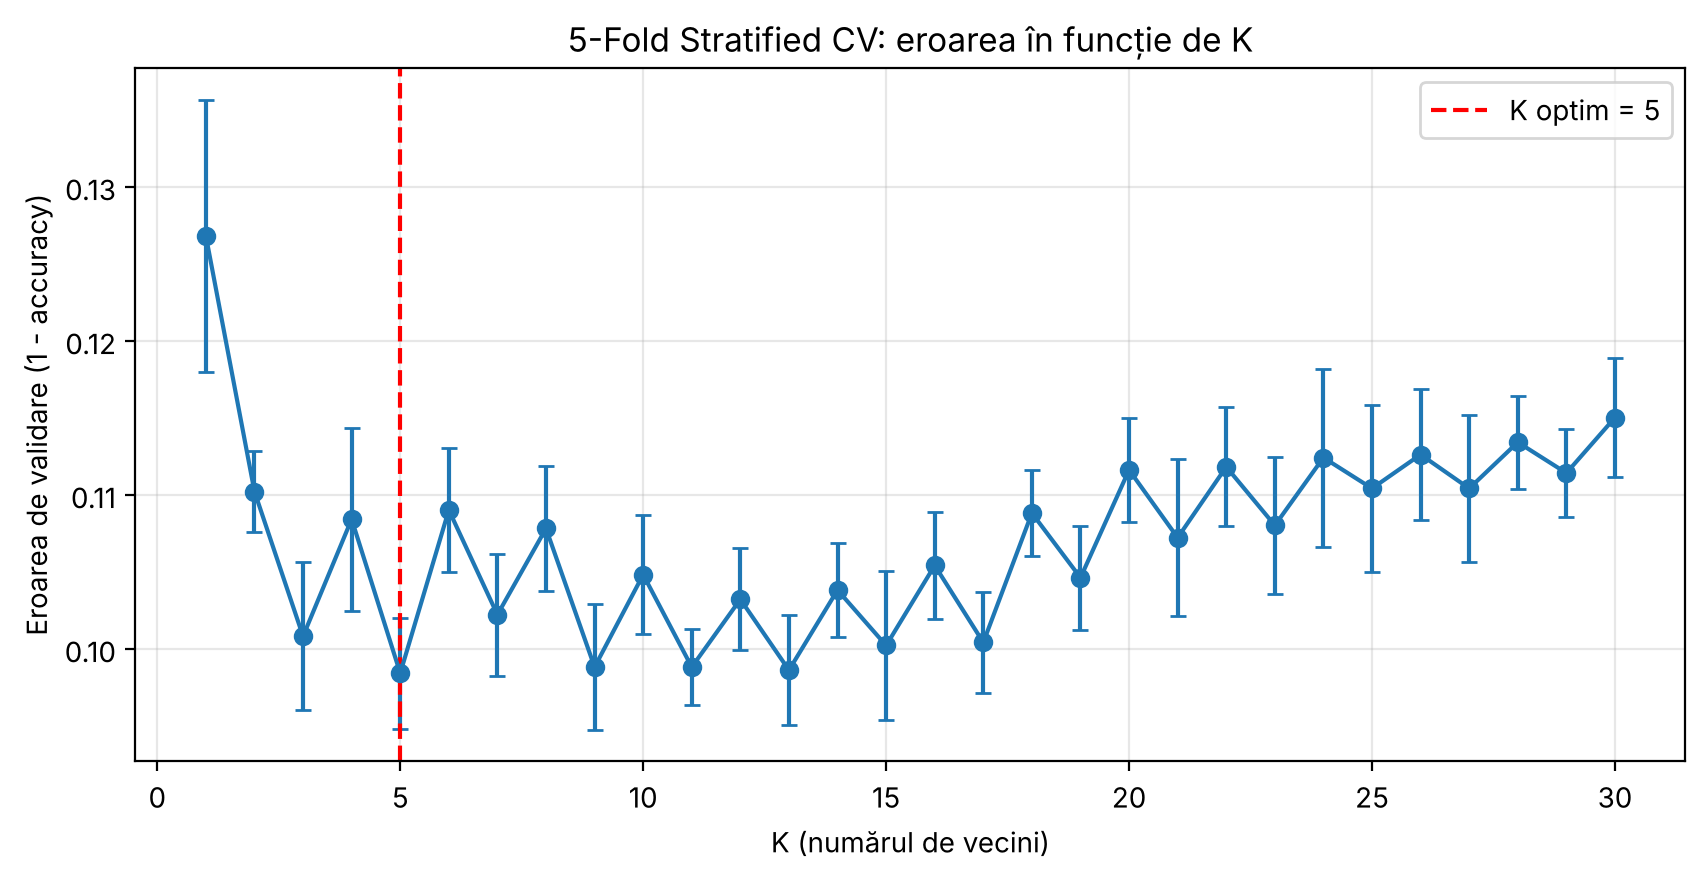

K optim = 5, acuratețe = 0.9016 ± 0.0036


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

X = df.drop(columns='churned').values
y = df['churned'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = range(1, 31)
means, stds = [], []

for k in k_values:
    # scaler în pipeline -> se ajustează doar pe fold-ul de antrenare (fără data leakage)
    model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy', n_jobs=-1)
    means.append(scores.mean()); stds.append(scores.std())

means, stds = np.array(means), np.array(stds)
errors = 1 - means
best_k = list(k_values)[np.argmax(means)]

print(f'{"K":>3} {"acc medie":>10} {"std":>8}')
for k, m, s in zip(k_values, means, stds):
    print(f'{k:>3} {m:10.4f} {s:8.4f}' + ('   <-- optim' if k == best_k else ''))

plt.figure(figsize=(10, 4.5))
plt.errorbar(list(k_values), errors, yerr=stds, marker='o', capsize=3)
plt.axvline(best_k, color='r', ls='--', label=f'K optim = {best_k}')
plt.xlabel('K (numărul de vecini)'); plt.ylabel('Eroarea de validare (1 - accuracy)')
plt.title('5-Fold Stratified CV: eroarea în funcție de K')
plt.legend(); plt.grid(alpha=.3); plt.show()
print(f'K optim = {best_k}, acuratețe = {means.max():.4f} ± {stds[np.argmax(means)]:.4f}')

### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)
În setul de date Orange Telecom, clasa majoritară este reprezentată de clienții care nu au renunțat (`churned = False`), iar cei care au renunțat reprezintă minoritatea. Explicați de ce metrica `accuracy` (acuratețea) în acest context este înșelătoare. Modificați codul de evaluare pentru a calcula Matricea de Confuzie (Confusion Matrix), Precision, Recall și F1-score utilizând `sklearn.metrics`.

Distribuția claselor:
 churned
0    0.859
1    0.141
Name: proportion, dtype: float64

Acuratețea clasificatorului naiv (mereu „nu pleacă”): 0.8587  | recall churn = 0.00
Acuratețea KNN (K=5): 0.8993

Matricea de confuzie:
 [[1263   25]
 [ 126   86]]

Precision: 0.7748 | Recall: 0.4057 | F1: 0.5325

               precision    recall  f1-score   support

  Rămâne (0)       0.91      0.98      0.94      1288
   Churn (1)       0.77      0.41      0.53       212

    accuracy                           0.90      1500
   macro avg       0.84      0.69      0.74      1500
weighted avg       0.89      0.90      0.89      1500



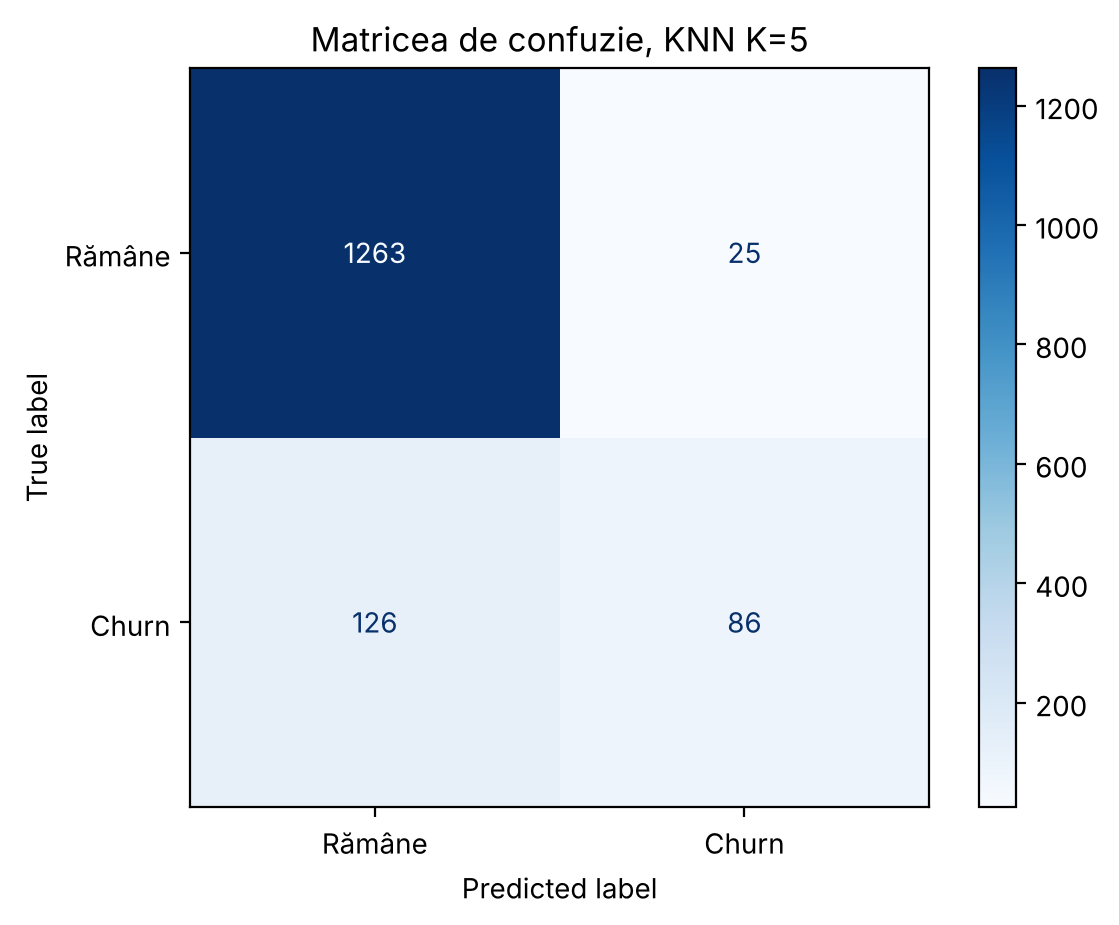

In [12]:
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, accuracy_score)

print('Distribuția claselor:\n', df['churned'].value_counts(normalize=True).round(3))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
model = make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_tr, y_tr)
y_pred = model.predict(X_te)

# Clasificator „naiv” care prezice mereu clasa majoritară
y_dummy = np.zeros_like(y_te)
print(f'\nAcuratețea clasificatorului naiv (mereu „nu pleacă”): {accuracy_score(y_te, y_dummy):.4f}  '
      f'| recall churn = {recall_score(y_te, y_dummy):.2f}')
print(f'Acuratețea KNN (K={best_k}): {accuracy_score(y_te, y_pred):.4f}')

print('\nMatricea de confuzie:\n', confusion_matrix(y_te, y_pred))
print('\nPrecision: %.4f | Recall: %.4f | F1: %.4f' % (
    precision_score(y_te, y_pred), recall_score(y_te, y_pred), f1_score(y_te, y_pred)))
print('\n', classification_report(y_te, y_pred, target_names=['Rămâne (0)', 'Churn (1)']))

ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=['Rămâne', 'Churn'], cmap='Blues')
plt.title(f'Matricea de confuzie, KNN K={best_k}'); plt.show()

**De ce acuratețea este înșelătoare.** Doar ~14% dintre clienți pleacă (churn = 1). Un „model” care spune mereu „clientul rămâne” obține ~86% acuratețe fără să găsească **niciun** client care pleacă (recall = 0). Acuratețea este dominată de clasa majoritară, iar pentru business important este exact clasa minoritară.

Metrici mai potrivite (pentru clasa pozitivă *churn*):
- **Precision** = TP / (TP + FP) – din clienții marcați ca „pleacă”, câți pleacă de fapt (costul ofertelor de retenție inutile);
- **Recall** = TP / (TP + FN) – câți dintre clienții care pleacă au fost găsiți (costul clienților pierduți);
- **F1** – media armonică a celor două; plus matricea de confuzie, ROC-AUC/PR-AUC.

Rezultat: KNN are accuracy ≈ 0.90 (doar cu ~4 puncte peste modelul naiv), dar **recall pentru churn ≈ 0.41** – modelul ratează aproape 60% din clienții care pleacă (126 din 212 în matricea de confuzie), deși acuratețea pare mare. Îmbunătățiri posibile: `class_weight` nu există în KNN, dar se poate face oversampling (SMOTE), alegerea pragului pe `predict_proba`, sau optimizarea lui K după F1 în loc de accuracy.

### Exercițiul 9: Impactul ponderilor distanței (`weights='distance'`) versus ponderi uniforme
Comparați comportamentul modelului KNN pentru `weights='uniform'` și `weights='distance'`. Scrieți un experiment în Python care evaluează sensibilitatea modelului la zgomot (valori anormale în spațiul caracteristicilor) pentru ambele tipuri de ponderi. Care variantă este mai vulnerabilă la zgomot și de ce?

Accuracy pe test curat:


,"uniform, K=5","uniform, K=15","uniform, K=31","distance, K=5","distance, K=15","distance, K=31"
0% zgomot,0.9313,0.9407,0.9380,0.9300,0.9380,0.9407
5% zgomot,0.9240,0.9367,0.9380,0.9160,0.9327,0.9353
10% zgomot,0.9020,0.9340,0.9367,0.8973,0.9273,0.9347
20% zgomot,0.8707,0.9193,0.9353,0.8373,0.9027,0.9260
30% zgomot,0.7907,0.8893,0.9067,0.7587,0.8487,0.8807


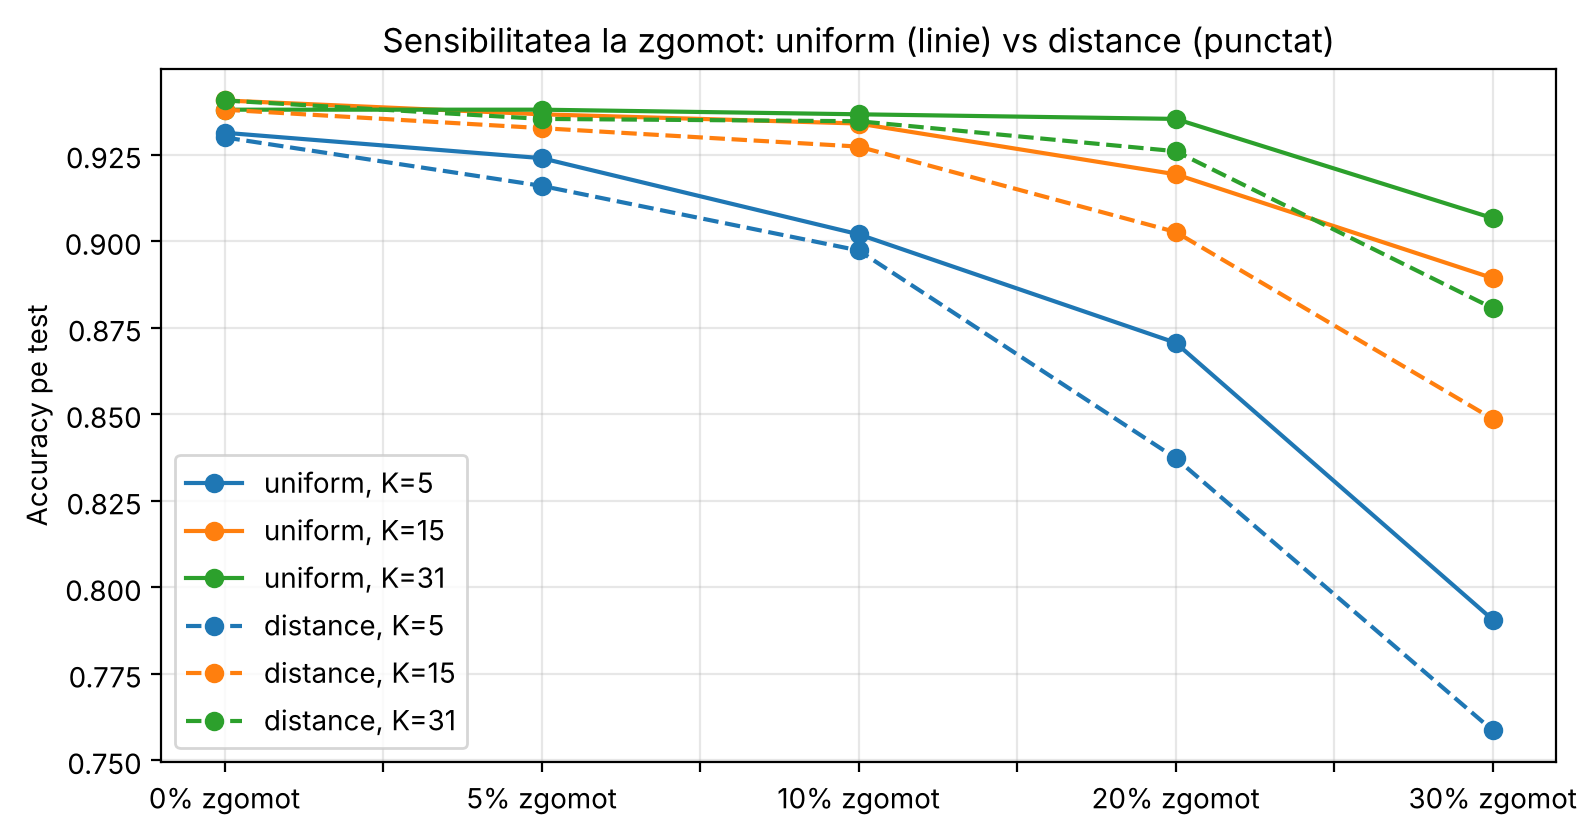

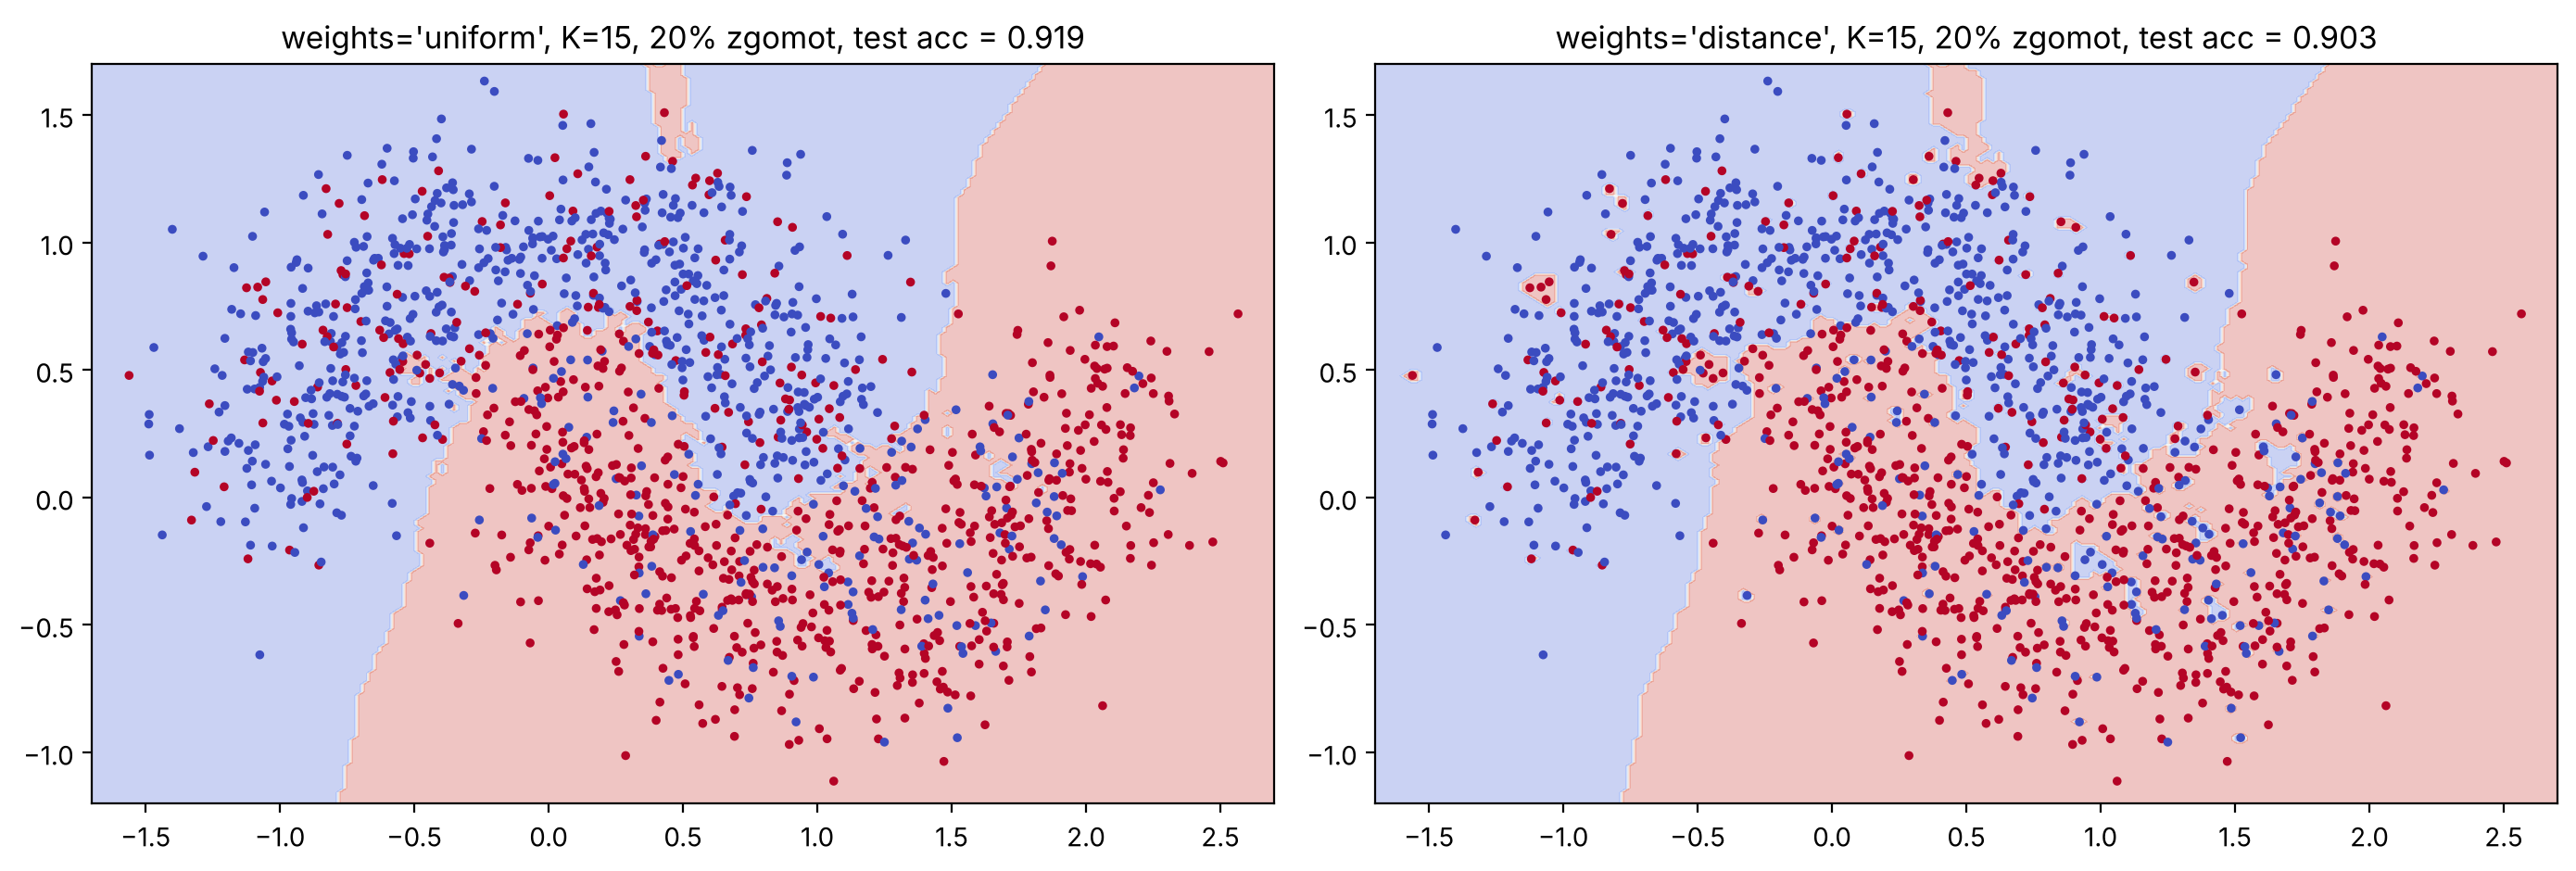

uniform : predicție = 0, probabilități = [0.8 0.2]
distance: predicție = 1, probabilități = [0.074 0.926]


In [13]:
# Experiment: zgomot de etichete (label noise) în setul de antrenare, evaluare pe test CURAT.
# Folosim un set 2D echilibrat (make_moons) ca efectul să fie clar și vizualizabil.
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=3000, noise=0.25, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.5, random_state=0)

def flip_labels(ya, frac, seed=0):
    rng = np.random.RandomState(seed)
    yn = ya.copy()
    idx = rng.choice(len(ya), int(frac * len(ya)), replace=False)
    yn[idx] = 1 - yn[idx]          # puncte „aberante”: eticheta greșită în mijlocul altei clase
    return yn

noise_levels = [0, 0.05, 0.1, 0.2, 0.3]
rows = {}
for frac in noise_levels:
    yn = flip_labels(ym_tr, frac)
    rows[f'{int(frac*100)}% zgomot'] = {
        f'{w}, K={k}': accuracy_score(ym_te, KNeighborsClassifier(n_neighbors=k, weights=w).fit(Xm_tr, yn).predict(Xm_te))
        for w in ['uniform', 'distance'] for k in [5, 15, 31]}
res_df = pd.DataFrame(rows).T
print('Accuracy pe test curat:'); display(res_df.round(4))

ax = res_df.plot(marker='o', figsize=(9, 4.5),
                 style=['-', '-', '-', '--', '--', '--'], color=['C0', 'C1', 'C2'] * 2)
ax.set_ylabel('Accuracy pe test'); ax.set_title('Sensibilitatea la zgomot: uniform (linie) vs distance (punctat)'); ax.grid(alpha=.3)
plt.show()

# Granițele de decizie cu 20% zgomot
yn = flip_labels(ym_tr, 0.2)
xx, yy = np.meshgrid(np.linspace(-1.7, 2.7, 200), np.linspace(-1.2, 1.7, 200))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, w in zip(axes, ['uniform', 'distance']):
    m = KNeighborsClassifier(n_neighbors=15, weights=w).fit(Xm_tr, yn)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=yn, cmap='coolwarm', s=6)
    ax.set_title(f"weights='{w}', K=15, 20% zgomot, test acc = {m.score(Xm_te, ym_te):.3f}")
plt.tight_layout(); plt.show()

# Ilustrare directă: punct de interogare chiar lângă un outlier cu etichetă greșită
pts = np.array([[0, 0], [0.1, 0], [0, 0.1], [0.1, 0.1], [0.05, 0.05]])   # 5 puncte, toate ar trebui să fie clasa 0
lab = np.array([0, 0, 0, 0, 1])                                           # ultimul = outlier etichetat greșit
q = np.array([[0.051, 0.051]])
for w in ['uniform', 'distance']:
    m = KNeighborsClassifier(n_neighbors=5, weights=w).fit(pts, lab)
    print(f'{w:8s}: predicție = {m.predict(q)[0]}, probabilități = {m.predict_proba(q)[0].round(3)}')

**Concluzii.**

- `weights='uniform'`: fiecare din cei K vecini are un vot egal ⇒ un punct zgomotos este doar 1 vot din K, efectul lui este „diluat” de vecinii corecți (netezire, varianță mai mică).
- `weights='distance'`: votul este ∝ 1/d. Un punct aberant (etichetă greșită) aflat **foarte aproape** de interogare primește o pondere uriașă și poate decide singur (exemplul de mai sus: 4 vecini corecți pierd în fața unui singur outlier, probabilitate 0.93). În jurul fiecărui punct zgomotos apar „insule” în granița de decizie.

Rezultatele confirmă: fără zgomot, cele două variante sunt practic egale, dar odată cu creșterea zgomotului acuratețea cu `distance` scade mai repede (la 30% zgomot, K=5: ~0.79 vs ~0.76; K=15: ~0.89 vs ~0.85). Deci **`weights='distance'` este mai vulnerabil la zgomot** – se comportă tot mai mult ca 1-NN (memorare, Ex. 5). `uniform` cu K suficient de mare este mai robust; `distance` este avantajos doar când datele sunt curate și densitatea claselor variază.

### Exercițiul 10: Blestemul dimensionalității (Curse of Dimensionality)
Algoritmul KNN se bazează pe măsurarea distanțelor în spații multidimensionale. Odată cu creșterea numărului de caracteristici, volumul spațiului crește exponențial, iar punctele devin echidistante. Scrieți un studiu de caz sau un experiment mic în Python care arată cum creșterea artificială a dimensionalității (adăugarea de coloane cu zgomot aleatoriu la datele de churn) înrăutățește performanța clasificatorului KNN.

,coloane totale,accuracy CV,F1 CV,(dmax-dmin)/dmin
coloane de zgomot,,,,
0,17,0.9034,0.5429,4.9407
5,22,0.8740,0.3269,3.7867
10,27,0.8614,0.2319,2.2130
20,37,0.8534,0.1441,1.2243
50,67,0.8510,0.0969,0.6209
100,117,0.8540,0.0562,0.3861
200,217,0.8542,0.0619,0.2663
500,517,0.8520,0.0463,0.1601


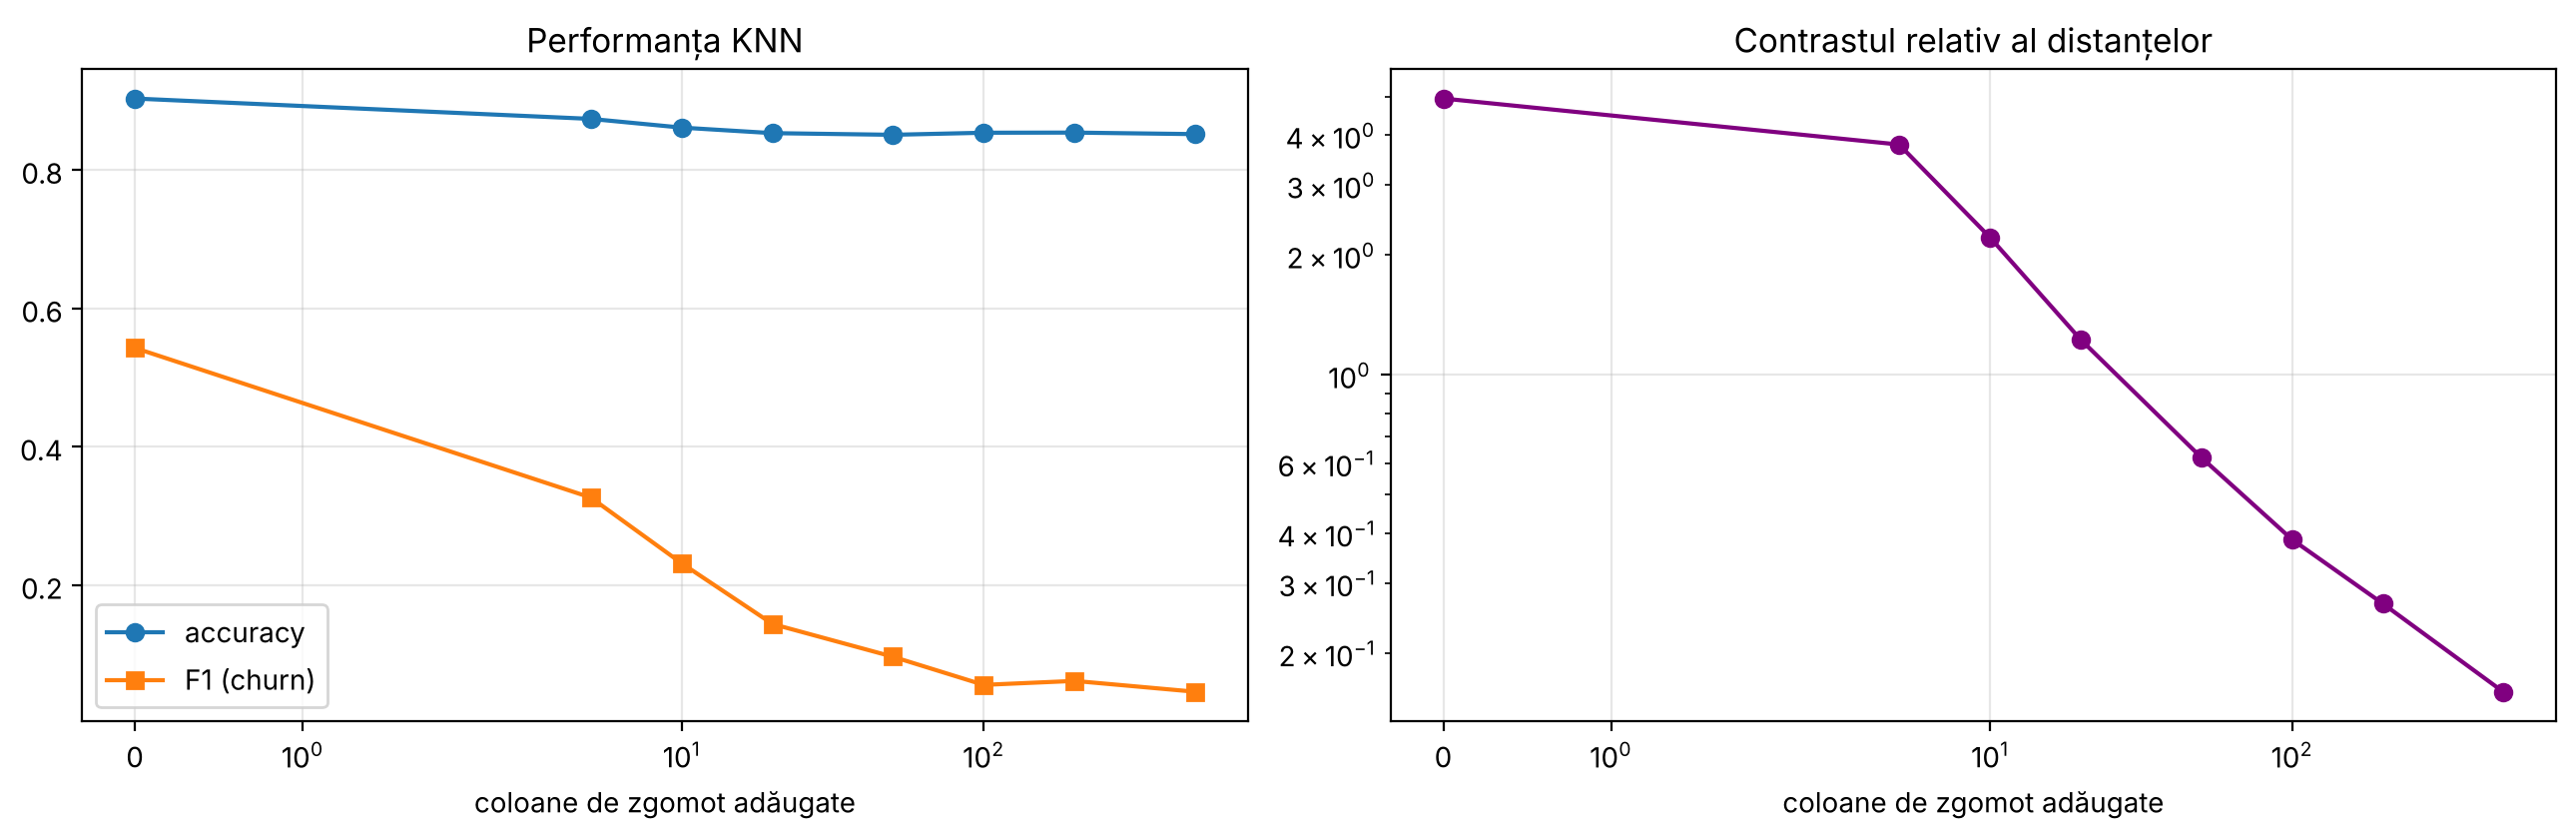

In [14]:
# Adăugăm coloane de zgomot uniform [0,1] (aceeași scară ca datele MinMax) și măsurăm performanța
rng = np.random.RandomState(RANDOM_STATE)
X_base = MinMaxScaler().fit_transform(X)
n_noise_list = [0, 5, 10, 20, 50, 100, 200, 500]
acc_list, f1_list, ratio_list = [], [], []

for n_noise in n_noise_list:
    Xn = np.hstack([X_base, rng.rand(len(X_base), n_noise)])
    model = KNeighborsClassifier(n_neighbors=best_k)
    acc_list.append(cross_val_score(model, Xn, y, cv=skf, scoring='accuracy', n_jobs=-1).mean())
    f1_list.append(cross_val_score(model, Xn, y, cv=skf, scoring='f1', n_jobs=-1).mean())
    # contrastul distanțelor: (d_max - d_min)/d_min pentru un punct de referință
    d = np.linalg.norm(Xn[1:1001] - Xn[0], axis=1)
    ratio_list.append((d.max() - d.min()) / d.min())

summary = pd.DataFrame({'coloane totale': X_base.shape[1] + np.array(n_noise_list),
                        'accuracy CV': acc_list, 'F1 CV': f1_list,
                        '(dmax-dmin)/dmin': ratio_list}, index=n_noise_list)
summary.index.name = 'coloane de zgomot'
display(summary.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(n_noise_list, acc_list, 'o-', label='accuracy'); ax[0].plot(n_noise_list, f1_list, 's-', label='F1 (churn)')
ax[0].set_xscale('symlog'); ax[0].set_xlabel('coloane de zgomot adăugate'); ax[0].set_title('Performanța KNN'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(n_noise_list, ratio_list, 'o-', color='purple'); ax[1].set_xscale('symlog'); ax[1].set_yscale('log')
ax[1].set_xlabel('coloane de zgomot adăugate'); ax[1].set_title('Contrastul relativ al distanțelor'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Concluzii.** Pe măsură ce adăugăm dimensiuni fără informație, F1 pentru clasa churn scade rapid (spre 0), iar acuratețea coboară spre nivelul clasificatorului naiv (~0.86). Explicația: contribuția celor 16 caracteristici utile la distanță este „înecată” de sute de dimensiuni aleatoare, iar contrastul relativ $(d_{max}-d_{min})/d_{min}$ scade spre 0 – toate punctele devin aproape **echidistante**, deci „cel mai apropiat vecin” devine practic aleator. Soluții: selecția caracteristicilor (`SelectKBest`, Ex. 12), reducerea dimensionalității (PCA), mai multe date.

### Exercițiul 11: KNN pentru regresie versus clasificare
Deși în notebook am folosit `KNeighborsClassifier` pentru o sarcină de clasificare binară, KNN este aplicabil și pentru regresie (`KNeighborsRegressor`). Scrieți un script care aplică `KNeighborsRegressor` pentru a prezice o variabilă continuă (de exemplu, `total_day_charges` pe baza minutelor și a apelurilor). Comparați funcția de pierdere (MSE — Mean Squared Error) pentru diferite valori ale lui K.

,MSE train,MSE test
K,,
1,0.0000,3.4375
2,0.6984,2.6767
3,0.8731,2.4280
5,0.9966,2.2796
7,1.1402,2.2161
10,1.3183,2.2931
15,1.6340,2.5639
20,1.8952,2.8687
30,2.4088,3.3656


K optim = 7, MSE test = 2.2161, R² = 0.9742
Regresie liniară, MSE test = 0.000009 (charge = 0.1700 * minute -> tarif fix)


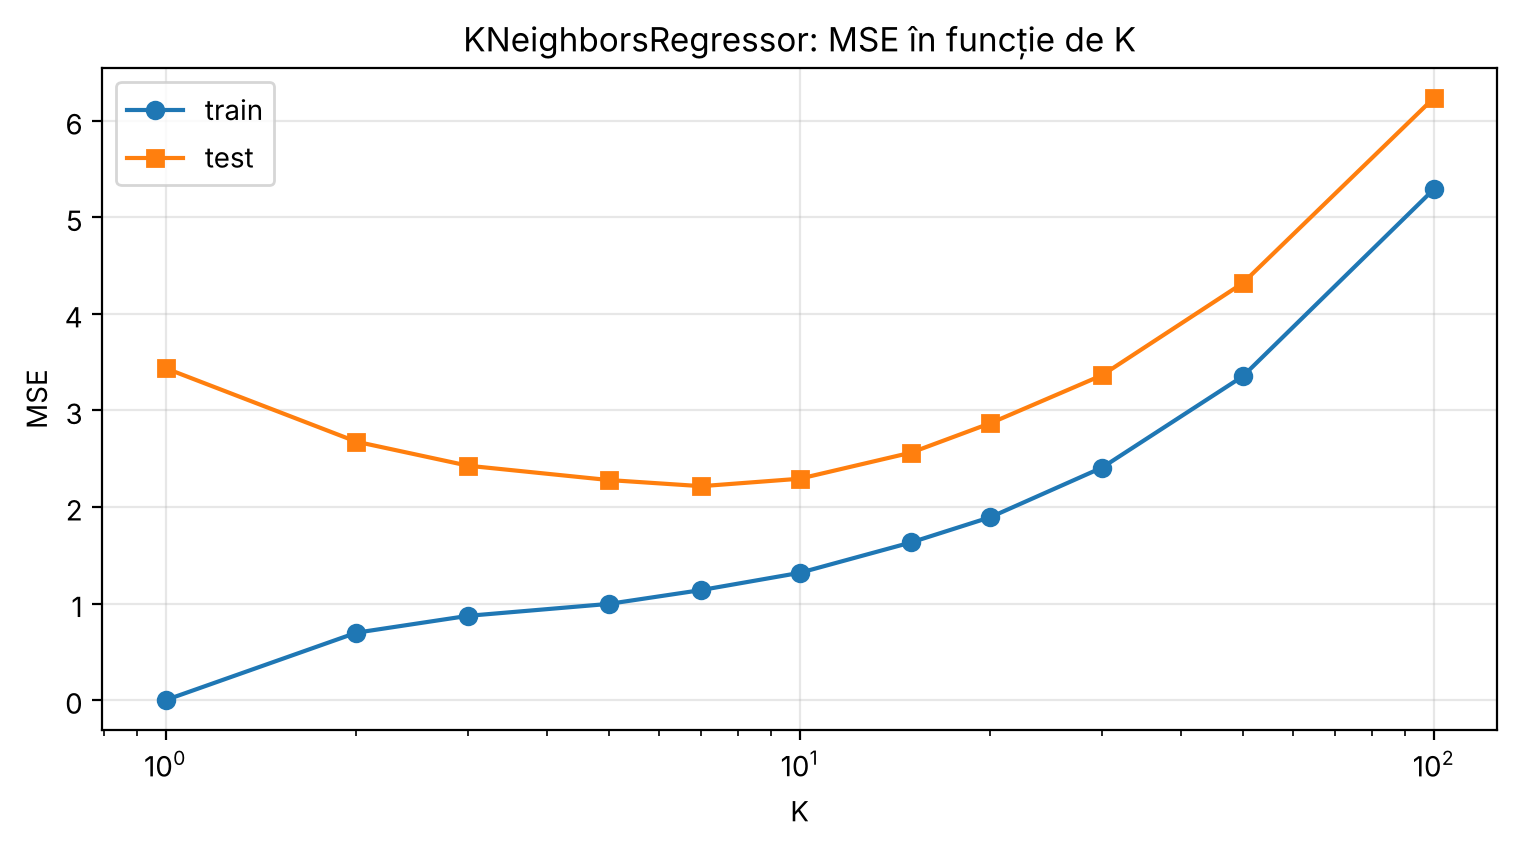

In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

# Țintă continuă: total_day_charge, prezisă din minute și numărul de apeluri (zi/seară)
features = ['total_day_minutes', 'total_day_calls', 'total_eve_minutes', 'total_eve_calls']
Xr = df[features].values
yr = df['total_day_charge'].values

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.3, random_state=RANDOM_STATE)
sc_r = MinMaxScaler().fit(Xr_tr)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100]
mse_tr, mse_te = [], []
for k in ks:
    reg = KNeighborsRegressor(n_neighbors=k).fit(Xr_tr_s, yr_tr)
    mse_tr.append(mean_squared_error(yr_tr, reg.predict(Xr_tr_s)))
    mse_te.append(mean_squared_error(yr_te, reg.predict(Xr_te_s)))

reg_df = pd.DataFrame({'MSE train': mse_tr, 'MSE test': mse_te}, index=pd.Index(ks, name='K'))
display(reg_df.round(4))
best_kr = ks[int(np.argmin(mse_te))]

lin = LinearRegression().fit(Xr_tr, yr_tr)
print(f'K optim = {best_kr}, MSE test = {min(mse_te):.4f}, '
      f'R² = {r2_score(yr_te, KNeighborsRegressor(best_kr).fit(Xr_tr_s, yr_tr).predict(Xr_te_s)):.4f}')
print(f'Regresie liniară, MSE test = {mean_squared_error(yr_te, lin.predict(Xr_te)):.6f} '
      f'(charge = {lin.coef_[0]:.4f} * minute -> tarif fix)')

plt.figure(figsize=(9, 4.3))
plt.plot(ks, mse_tr, 'o-', label='train'); plt.plot(ks, mse_te, 's-', label='test')
plt.xscale('log'); plt.xlabel('K'); plt.ylabel('MSE'); plt.title('KNeighborsRegressor: MSE în funcție de K')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Concluzii.** În regresie KNN prezice **media** țintelor celor K vecini (sau media ponderată), în loc de votul majoritar; funcția de pierdere este MSE în loc de accuracy. La K=1 MSE pe train = 0 (memorare), dar pe test este mai mare; cu K mic modelul are varianță mare, cu K foarte mare (50–100) predicțiile se netezesc prea mult (bias mare) și MSE crește din nou – curba în formă de U arată compromisul bias–varianță. Observație: `total_day_charge` este practic `0.17 × total_day_minutes` (tarif fix), de aceea regresia liniară obține MSE ≈ 0 – un exemplu că KNN nu este cea mai bună alegere când relația este simplă și liniară, iar celelalte caracteristici (apeluri, seara) doar adaugă zgomot în distanță.

### Exercițiul 12: Conducte de învățare automată cu `Pipeline` și `GridSearchCV`
Construiți o conductă (pipeline) completă în Scikit-learn care include: (1) `MinMaxScaler`, (2) opțional un selector de caracteristici (`SelectKBest`) și (3) `KNeighborsClassifier`. Utilizați `GridSearchCV` pentru căutarea simultană a hiperparametrilor optimi: numărul de vecini K din {3, 5, 7, 9, 11}, tipul de ponderi (`uniform`, `distance`) și metrica distanței (p=1 sau p=2). Afișați cel mai bun set de hiperparametri și scorul pe eșantionul de test.

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

feature_names = df.drop(columns='churned').columns
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(score_func=f_classif)),
    ('knn',    KNeighborsClassifier()),
])

param_grid = {
    'select__k':        [5, 8, 12, 'all'],
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights':     ['uniform', 'distance'],
    'knn__p':           [1, 2],
}

grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                    scoring='f1', n_jobs=-1)
grid.fit(X_tr, y_tr)

print('Cei mai buni hiperparametri:', grid.best_params_)
print(f'Cel mai bun F1 (CV): {grid.best_score_:.4f}')

y_pred = grid.predict(X_te)
print(f'\nPe eșantionul de test: accuracy = {accuracy_score(y_te, y_pred):.4f}, F1 = {f1_score(y_te, y_pred):.4f}')
print(classification_report(y_te, y_pred, target_names=['Rămâne', 'Churn']))

mask = grid.best_estimator_.named_steps['select'].get_support()
print('Caracteristici selectate:', list(feature_names[mask]))

top = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')[
    ['param_select__k', 'param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p', 'mean_test_score', 'std_test_score']].head(10)
display(top)

Cei mai buni hiperparametri: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'uniform', 'select__k': 12}
Cel mai bun F1 (CV): 0.6131

Pe eșantionul de test: accuracy = 0.9173, F1 = 0.6395
              precision    recall  f1-score   support

      Rămâne       0.93      0.98      0.95      1288
       Churn       0.83      0.52      0.64       212

    accuracy                           0.92      1500
   macro avg       0.88      0.75      0.80      1500
weighted avg       0.91      0.92      0.91      1500

Caracteristici selectate: ['intl_plan', 'voice_mail_plan', 'number_vmail_messages', 'total_day_minutes', 'total_day_charge', 'total_eve_minutes', 'total_eve_charge', 'total_night_charge', 'total_intl_minutes', 'total_intl_calls', 'total_intl_charge', 'number_customer_service_calls']


,param_select__k,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_score,std_test_score
2,12,3,uniform,1,0.613082,0.022479
6,12,3,distance,1,0.611768,0.024868
17,8,5,uniform,1,0.610995,0.049053
33,8,7,uniform,1,0.610856,0.053575
37,8,7,distance,1,0.610852,0.054494
5,8,3,distance,1,0.608975,0.043704
9,8,3,uniform,2,0.606664,0.048091
1,8,3,uniform,1,0.606042,0.039545
22,12,5,distance,1,0.604932,0.036178
18,12,5,uniform,1,0.602813,0.036443


**Concluzii.** `Pipeline` garantează că scalarea și selecția caracteristicilor se ajustează doar pe fold-urile de antrenare (fără scurgere de informație), iar `GridSearchCV` testează toate cele 4×5×2×2 = 80 combinații cu validare încrucișată 5-fold (400 de antrenări). Am optimizat după **F1**, nu accuracy, din cauza dezechilibrului claselor (Ex. 8). Cea mai bună combinație: K=3, `weights='uniform'`, p=1 (Manhattan) și 12 caracteristici selectate (au fost eliminate cele fără legătură cu churn: `account_length`, numărul de apeluri zi/seară/noapte etc.). Pe test F1 pentru churn a crescut de la ~0.53 (Ex. 8, toate coloanele) la ~0.64, iar accuracy la ~0.92 – o confirmare practică a Ex. 10: dimensiunile irelevante strică KNN-ul.